<a href="https://colab.research.google.com/github/zmgriffin/Data201-labs/blob/main/homework%5CWeek9_HW_Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Week 9 Assignment: Decision Trees (Carseats)

Zachary Griffin; Fall 2026


### Part 1: Build a Classification Tree
1. Load the Carseats dataset and create the binary target HighSales. (copy the code from
the lab)
2. Encode categorical predictors.
3. Split the data into 70% training and 30% test sets.
4. Train a DecisionTreeClassifier with max_depth=3.
5. Plot the tree and report training and test accuracy.

In [1]:
%pip -q install ISLP


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [3]:
# copied from lab
from ISLP import load_data
carseats = load_data('Carseats')

carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [4]:
#copied from lab, per instructions
# Convert Sales into categories: High = 1, Low = 0
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales'])

# Check the number of stores in each category
print(carseats['HighSales'].value_counts())

HighSales
0    236
1    164
Name: count, dtype: int64


In [5]:
# check missing values
print(carseats.isna().sum())

CompPrice      0
Income         0
Advertising    0
Population     0
Price          0
ShelveLoc      0
Age            0
Education      0
Urban          0
US             0
HighSales      0
dtype: int64


In [6]:
#split data

X = pd.get_dummies(carseats.drop(columns= 'HighSales'), columns = ['ShelveLoc', 'Urban', 'US']).astype(int)
y = carseats['HighSales']

#train-test split, 30% for test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=13, stratify=y)

print(X_train.shape, X_test.shape)

X_train.head()

(280, 14) (120, 14)


,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Bad,ShelveLoc_Good,ShelveLoc_Medium,Urban_No,Urban_Yes,US_No,US_Yes
330,122,59,0,501,112,32,14,1,0,0,1,0,1,0
151,111,58,17,407,103,75,17,0,1,0,1,0,0,1
153,150,36,7,488,150,25,17,0,0,1,1,0,0,1
390,108,75,9,61,111,67,12,0,0,1,0,1,0,1
266,128,93,12,343,112,73,17,0,1,0,1,0,0,1


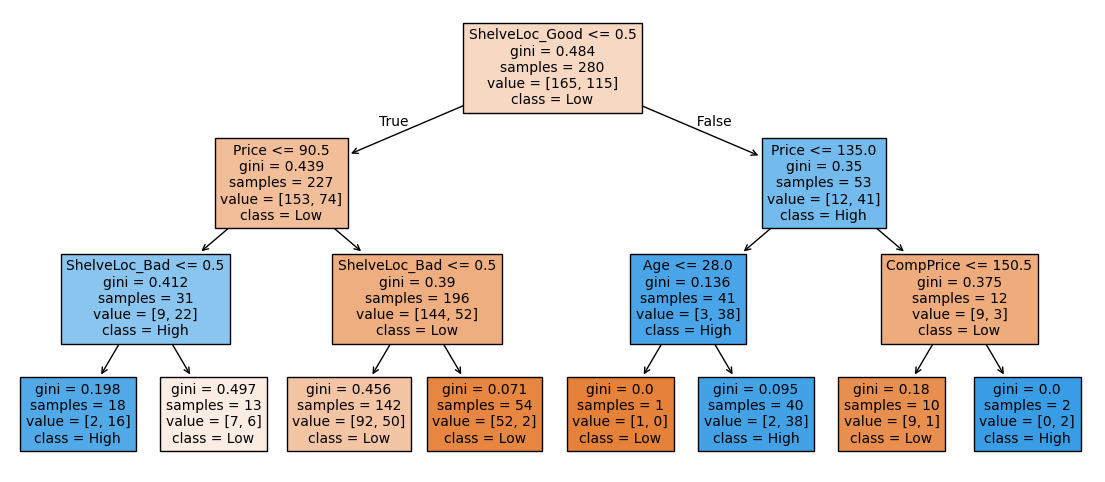

Train accuracy: 0.775
Test accuracy:  0.725


In [7]:
# creating a tree with max depth 3
tree3 = DecisionTreeClassifier(max_depth= 3, random_state = 2)

tree3.fit(X_train, y_train)

# make the figure
plt.figure(figsize=(14, 6))

plot_tree(tree3,
          feature_names=list(X.columns),
          class_names = ["Low", "High"], # Low was zero, High was 1
          filled = True, # darker color = higher purity in leaf
          fontsize = 10)
plt.show()

print('Train accuracy:', round(tree3.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree3.score(X_test, y_test), 3))

### Part 2: Investigate Overfitting
1. Train decision trees with max_depth values from 1 to 10.
2. Use 5-fold cross-validation on the training data to calculate mean accuracy for each
depth.
3. Create a graph showing tree depth versus cross-validation accuracy.
4. Identify the best depth based on cross-validation.
5. Train a final tree using that depth and evaluate it on the test set.

In [8]:
# finding the best depth using 5-fold CV
grid = GridSearchCV(
      DecisionTreeClassifier(random_state=2),
      param_grid={'max_depth': [1, 2, 3, 4, 5, 6, 8, 10]},
      cv=5)

grid.fit(X_train, y_train)



print('Best settings:', grid.best_params_)
print('Best CV accuracy:', round(grid.best_score_, 3))

Best settings: {'max_depth': 6}
Best CV accuracy: 0.732


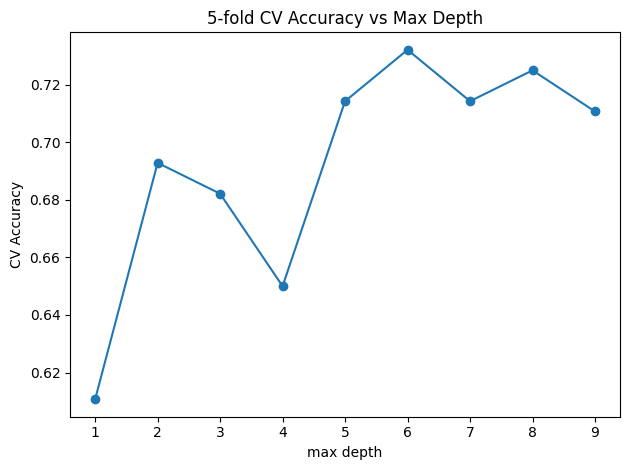

In [9]:
# Graphing CV accuracy vs max depth
depths = range(1,10)
cv_acc = []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=2).fit(X_train, y_train)
    cv_acc.append(cross_val_score(m, X_train, y_train, cv=5).mean()) # find the mean cv score for every tree

plt.plot(depths, cv_acc, marker='o')
plt.xlabel('max depth'); plt.ylabel('CV Accuracy')
plt.title('5-fold CV Accuracy vs Max Depth' )
plt.tight_layout()
plt.show()
# see how the highest accuracy matches the GridSearch result above

In [10]:
# training a tree on depth 6:
tree6 = DecisionTreeClassifier(max_depth= 6, random_state = 2)

tree6.fit(X_train, y_train)

# The figure does not fit well. At all.
# plt.figure(figsize=(37, 30))

# plot_tree(tree6,
#           feature_names=list(X.columns),
#           class_names = ["Low", "High"], # Low was zero, High was 1
#           filled = True, # darker color = higher purity in leaf
#           fontsize = 10)
# plt.show()

print('Test accuracy: ', round(tree6.score(X_test, y_test), 3))

Test accuracy:  0.708


In [11]:
# finding  the root predictor via for the next question
root = X_train.columns[tree6.tree_.feature[0]]
thr = tree6.tree_.threshold[0]
print("root:", root, "<=", thr )

root: ShelveLoc_Good <= 0.5


### Part 3: Answer the Following Questions
1. Interpreting the tree: Which predictor was selected for the first split (root)? What does
this split tell us about sales?

*ShelveLoc_Good. This tells us that the purest leaves were achieved by splitting first by asking if the  Shelving location was 'Good' or not (the other two options), indicating that location in the store is important.*

2. Choosing tree depth: According to your cross-validation graph, which depth performed
best? Why should we use cross-validation rather than test accuracy to choose the depth?

*Depth 6 performed the best. We cross-validation instead of test-accuracy to avoid test data leakage, as well as to decrease the chance a single particularly lucky or unlucky train=test split.*

3. Overfitting: Does increasing tree depth always improve cross-validation accuracy?
Explain using your graph.

*No, the graph shows that there are dips in the CV accuracy. For this sample, particulary between depths of two and four.*

### Wrap-up Questions from Week 9 Lab:

1. What does a leaf predict in a classification tree? In a regression tree?

*On regression trees, leaves predict the mean of the training observations within. In a classification tree, it predicts the majority class in the leaf.*

2. Why did the full tree reach 100% training accuracy but do worse on the test set?
*The full tree learns the training set and is able to split to minimize impurities. The testing set however is new data and always have at least some differeces.*

3. Give two ways to limit tree complexity. Which one did cross-validation help you tune?
*Pre-prune with max depth or max leaf nodes. CV grid search can find the best, or they can be pre-selected. Post-pruning requires cross-validation to find the best alpha.*

4. Why do we not need to scale features before fitting a tree?

*Each feature is only being compared to a theshold determined by it's own range of values.*

5. A teammate says "Age has importance 0, so it is irrelevant to heart disease." What is wrong with that claim? (answer in terms of reducing impurity)

*Importance is ranked by which features reduce the leaf impurity, not by actually being irrelevent. Other features may give the same information or be correleated to age.*

6. Name one strength and one weakness of a single decision tree that you saw in this lab.

*They're fairly simple (when not too deep) and easy to follow/explain, but will vary greatly on the training sample.*